# Lab 5 — Computer vision with LLMs

A CNN classifier answers one fixed question: *which of my N classes is this?*  
A vision-language model (VLM) takes an image **and a prompt**, so the question is yours to choose.

In this lab you will:

1. Ask two local vision models (via [Ollama](https://ollama.com)) the same questions about one photo and compare the answers.
2. Climb a ladder of question types: describe → read → count → infer → cannot be known from the image.
3. Make a VLM behave like a tagging API by asking for JSON, and compare it with the Azure Image Analysis tags from Lab 3.
4. (Optional) Send the same image to a hosted model on Azure OpenAI.

**Setup:** install Ollama, then pull two vision-capable models, for example

```bash
ollama pull gemma3
ollama pull llama3.2-vision
```

Any model that lists `vision` under `ollama show <model>` works. Set `VISION_MODELS` to pick different ones.

Models: ['gemma3', 'gemma4']
nyc-street.jpg (1200, 800)


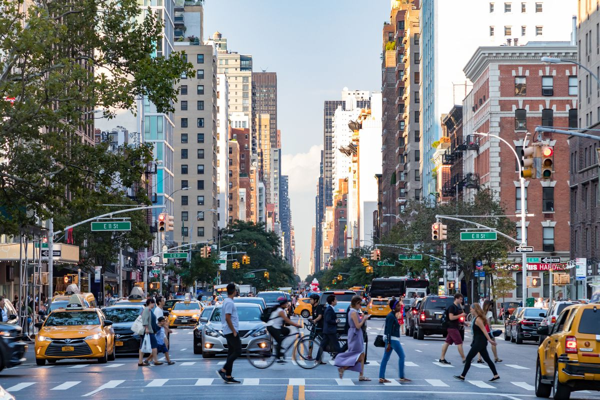

In [5]:
import base64, json, os, time
from pathlib import Path

import ollama
from PIL import Image
from dotenv import load_dotenv

load_dotenv()

# Comma-separated list of Ollama models to compare
MODELS = [m.strip() for m in os.getenv("VISION_MODELS", "gemma3,llama3.2-vision").split(",")]
IMAGE = Path("..") / ".." / "images" / "nyc-street.jpg"

print("Models:", MODELS)
img = Image.open(IMAGE)
print(IMAGE.name, img.size)
display(img.resize((600, 400)))

In [6]:
import os
os.environ["VISION_MODELS"] = "gemma3,gemma4"

## 1. One helper, any model

The Ollama chat API accepts a list of image paths next to the text of a user message. `temperature=0` makes the answers as repeatable as the model allows.

In [7]:
def ask(model, question, image=IMAGE, **kwargs):
    """Send one image + one question to a local Ollama vision model."""
    start = time.time()
    response = ollama.chat(
        model=model,
        messages=[{"role": "user", "content": question, "images": [str(image)]}],
        options={"temperature": 0},
        **kwargs,
    )
    return response["message"]["content"].strip(), time.time() - start


def compare(question, models=MODELS):
    print(f"Q: {question}")
    for model in models:
        answer, seconds = ask(model, question + " Answer in at most two sentences.")
        print(f"\n[{model}  {seconds:.1f}s]\n{answer}")
    print("-" * 80)

## 2. The question ladder

Each step asks for something a fixed-label classifier could not give you. Watch where the two models start to disagree, and where they answer confidently when the honest answer is *the image does not say*.

In [8]:
QUESTIONS = [
    # describe
    "Describe this picture.",
    # read text in the scene (OCR)
    "What street is this? Read it from the signs.",
    # count
    "How many yellow taxis are visible?",
    # infer from evidence
    "Why are the people walking while the cars are not moving?",
    "Is it a hot day? What in the picture tells you?",
    # not answerable from pixels alone
    "What year was this photo taken?",
]

for q in QUESTIONS:
    compare(q)

Q: Describe this picture.

[gemma3  7.2s]
This vibrant photograph captures a busy street scene in New York City, filled with yellow taxis, pedestrians, and cyclists navigating a dense urban environment. Tall buildings line the street, illuminated by the warm glow of the late afternoon or early evening light.

[gemma4  16.9s]
This is a bustling street scene in a dense urban environment, characterized by a canyon of towering, varied skyscrapers. Pedestrians walk across the crosswalk while traffic moves through the busy intersection under a bright sky.
--------------------------------------------------------------------------------
Q: What street is this? Read it from the signs.

[gemma3  6.8s]
Based on the signs in the image, this is East Houston Street. The signs clearly indicate the street name as "E. H. ST."

[gemma4  13.7s]
Based on the signs visible in the image, this street is E 11 St.
--------------------------------------------------------------------------------
Q: How many yell

### Discuss

- Which answers can you verify by looking at the photo yourself? Which can you not?
- Did either model refuse or hedge on the last question, or did it guess a year?
- Counting is a known weak spot for VLMs. Count the taxis yourself and compare.

## 3. A VLM as a tagging API

Lab 3 called Azure Image Analysis, which returns a fixed JSON schema of tags with confidences. A VLM can produce the same shape if you ask for it. `format="json"` constrains the model to emit valid JSON.

In [9]:
TAG_PROMPT = (
    "List the 8 most important things visible in this image. "
    'Respond with JSON only, in the form {"tags": ["tag1", "tag2", ...], "caption": "one sentence"}.'
)

for model in MODELS:
    raw, seconds = ask(model, TAG_PROMPT, format="json")
    try:
        parsed = json.loads(raw)
        print(f"[{model}  {seconds:.1f}s]")
        print("  tags:   ", parsed.get("tags"))
        print("  caption:", parsed.get("caption"))
    except json.JSONDecodeError:
        print(f"[{model}] did not return valid JSON:\n{raw[:300]}")

[gemma3  8.6s]
  tags:    ['New York City', 'street', 'traffic', 'buildings', 'pedestrians', 'yellow taxis', 'streetlights', 'urban']
  caption: This image captures a busy street scene in New York City with traffic, pedestrians, and tall buildings lining the avenue.
[gemma4  19.4s]
  tags:    ['City', 'Skyscrapers', 'Traffic', 'Pedestrians', 'Street', 'Buildings', 'Trees', 'Urban']
  caption: A busy urban street scene where pedestrians navigate traffic beneath a canopy of towering city buildings.


Compare with the Azure Image Analysis output for the Times Square photo in Lab 3: `building 0.99, metropolis 0.94, downtown 0.93, …`

| | Azure Image Analysis | Vision LLM |
|---|---|---|
| Output | Fixed schema, confidence scores | Whatever you ask for; no calibrated confidence |
| Repeatable | Yes | Mostly, at temperature 0 |
| Follow-up questions | No | Yes |
| Speed / cost per image | Milliseconds, fractions of a cent | Seconds, more tokens |

## 4. Optional — the same call on Azure OpenAI

Hosted multimodal models take the image as a base64 data URL inside the chat message. This cell runs only if these are set in your `.env`:

```
AZURE_OPENAI_ENDPOINT=https://<your-resource>.openai.azure.com/
AZURE_OPENAI_API_KEY=...
AZURE_OPENAI_DEPLOYMENT=<name of a vision-capable chat deployment>
```

In [ ]:
def ask_azure(question, image=IMAGE):
    from openai import AzureOpenAI

    client = AzureOpenAI(
        azure_endpoint=os.environ["AZURE_OPENAI_ENDPOINT"],
        api_key=os.environ["AZURE_OPENAI_API_KEY"],
        api_version=os.getenv("AZURE_OPENAI_API_VERSION", "2024-10-21"),
    )
    b64 = base64.b64encode(Path(image).read_bytes()).decode()
    response = client.chat.completions.create(
        model=os.environ["AZURE_OPENAI_DEPLOYMENT"],
        messages=[{
            "role": "user",
            "content": [
                {"type": "text", "text": question},
                {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{b64}"}},
            ],
        }],
    )
    return response.choices[0].message.content


if all(os.getenv(k) for k in ("AZURE_OPENAI_ENDPOINT", "AZURE_OPENAI_API_KEY", "AZURE_OPENAI_DEPLOYMENT")):
    for q in QUESTIONS[:3]:
        print("Q:", q, "\nA:", ask_azure(q), "\n")
else:
    print("Azure OpenAI variables not set; skipping this section.")

Azure OpenAI variables not set; skipping this section.


## 5. Your turn

1. Add three questions of your own to `QUESTIONS`: one the photo clearly answers, one that needs reasoning, and one it cannot answer. Did the models tell the difference?
2. Point `IMAGE` at a landmark in `images/` (`effeilTower.jpeg`, `tajMajal.jpeg`, `sydneyOpera.jpeg`) and ask *"Which landmark is this, and in which city?"* Compare with the `landmarks` detail Azure returned in Lab 3.
3. Point `IMAGE` at one of the hand-drawn digits in `labs/02-keras-cnn/samples/` and ask which digit it is. Your 93,322-weight CNN from Lab 2 does this in a millisecond. When is the multi-billion-weight model the right tool, and when is it not?